# №10 зертханалық жұмыс
## Feature Importance, Permutation Importance және SHAP пайдаланып белгілер маңыздылығын талдау және модель нәтижелерін интерпретациялау.

Бір кездейсоқ орман, WDBC жиынының бір бекітілген бөлінуі және талдаудың үш түрі. Есептеулер жергілікті орындалады. Қасында 9-тараудың CSV файлы қолжетімді болса, ол дәл салыстырылады. Болжамдар, жіктеулер және суреттер `lab10_artifacts` ішіне сақталады.

[WDBC, DOI 10.24432/C5DW2B және CC BY 4.0](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic).

### Орта және хаттама

Нұсқаларды, орман конфигурациясын, оң класты және топ белгілерін бекітеміз. PFI ROC-AUC кемуі бойынша бағаланады. Жергілікті SHAP үлестері 1 класының ықтималдық бірліктерімен өрнектеледі.

In [1]:
from hashlib import sha256
from importlib.metadata import version
from pathlib import Path
import json
import os
import platform

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from threadpoolctl import threadpool_limits

ROOT = Path.cwd() / "lab10_artifacts"
FIGURES = ROOT / "figures"
relative_csv = Path("datasets/wdbc_boosting.csv")
csv_candidates = [Path.cwd() / relative_csv, Path.cwd().parent / relative_csv]
DATASET = next((path for path in csv_candidates if path.is_file()), csv_candidates[0])
FIGURES.mkdir(parents=True, exist_ok=True)
PACKAGES = ("numpy", "pandas", "scikit-learn", "matplotlib", "threadpoolctl", "shap")
THREAD_ENVIRONMENT = ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                      "BLIS_NUM_THREADS", "NUMEXPR_NUM_THREADS")
FOREST = {"n_estimators": 200, "max_depth": 6, "min_samples_leaf": 2,
          "max_features": "sqrt", "n_jobs": 1, "random_state": 2026}
GROUP = ["mean_radius", "mean_perimeter", "mean_area"]
REPEATS = 30
plt.rcParams["font.family"] = "DejaVu Sans"


from IPython.display import Image, display

for package in PACKAGES:
    print(package, version(package))


numpy 2.5.4
pandas 3.0.1
scikit-learn 1.9.1
matplotlib 3.11.2
threadpoolctl 3.7.0
shap 0.54.1


### 1–2-қадамдар. Деректер және бөлу

569 жол жүктеп, 30 белгіні бөліп аламыз, бастапқы 0 белгісін 1 класы ретінде кодтаймыз. Seed 2026 бар стратификацияланған бөлуде 455 train жолын және 114 test жолын аламыз.

In [2]:
def prepare_data(csv_path=DATASET):
    source = load_breast_cancer()
    names = [name.replace(" ", "_") for name in source.feature_names]
    X = pd.DataFrame(source.data, columns=names)
    y = (source.target == 0).astype(int)
    train, test = train_test_split(np.arange(len(y)), test_size=.2, stratify=y, random_state=2026)
    source_check = {"csv_verified_exact": False, "license": "CC BY 4.0", "DOI": "10.24432/C5DW2B"}
    if csv_path.is_file():
        csv = pd.read_csv(csv_path, float_precision="round_trip")
        membership = np.full(len(y), "test", dtype=object)
        membership[train] = "train"
        if csv.columns.tolist() != names + ["row_id", "malignant", "split"]:
            raise ValueError("9-тараудың WDBC экспортында күтілмеген бағандар бар")
        np.testing.assert_array_equal(csv[names].to_numpy(), X.to_numpy())
        np.testing.assert_array_equal(csv["row_id"], np.arange(len(y)))
        np.testing.assert_array_equal(csv["malignant"], y)
        np.testing.assert_array_equal(csv["split"], membership)
        source_check.update({"csv_verified_exact": True, "csv_filename": csv_path.name,
                             "csv_sha256": sha256(csv_path.read_bytes()).hexdigest()})
    return {"X": X, "y": y, "train": train, "test": test, "source": source_check}


data = prepare_data()
print("Train және test өлшемдері", len(data["train"]), len(data["test"]))
print("Train класс жиіліктері", np.bincount(data["y"][data["train"]]))
print("Test класс жиіліктері", np.bincount(data["y"][data["test"]]))
print("CSV дәл салыстырылды", data["source"]["csv_verified_exact"])


Train және test өлшемдері 455 114
Train класс жиіліктері [285 170]
Test класс жиіліктері [72 42]
CSV дәл салыстырылды True


### 3-қадам. Орманды оқыту

Орман train ішінде алдын ала берілген тереңдік, ағаштар саны, жапырақ өлшемі, max_features баптауы және seed арқылы оқытылады.

In [3]:
def fit_forest(data):
    forest = RandomForestClassifier(**FOREST)
    with threadpool_limits(limits=1):
        forest.fit(data["X"].iloc[data["train"]], data["y"][data["train"]])
    return forest


def positive_probabilities(model, X):
    column = int(np.flatnonzero(model.classes_ == 1)[0])
    return model.predict_proba(X)[:, column]


def auc_positive(model, X, y):
    return roc_auc_score(y, positive_probabilities(model, X))


model = fit_forest(data)
print("Кластар", model.classes_)
print("Ағаштар саны", len(model.estimators_))


Кластар [0 1]
Ағаштар саны 200


### 4–7-қадамдар. ROC-AUC, MDI және PFI

Бастапқы тест матрицасындағы ROC-AUC сақтаймыз. MDI үлестерін орманнан аламыз. Әр бағанның 30 жеке алмастыруын және 30 топтық қайталауды есептейміз. Топтық қайталауда үш бағанның бәріне жолдардың бір реті қолданылады. Суреттегі мұртшалар алмастырулар бойынша стандарттық ауытқуды білдіреді.

Тест ROC-AUC: 0.994378307
             feature      MDI  PFI_mean   PFI_sd
worst_concave_points 0.115224  0.001047 0.001457
       worst_texture 0.018750  0.000959 0.000594
        mean_texture 0.012057  0.000761 0.000513
     worst_perimeter 0.104737  0.000761 0.000920
          worst_area 0.127399  0.000694 0.001131
           mean_area 0.053863  0.000628 0.000312
Топтық PFI орташа мәні 0.001807760, SD 0.001262787


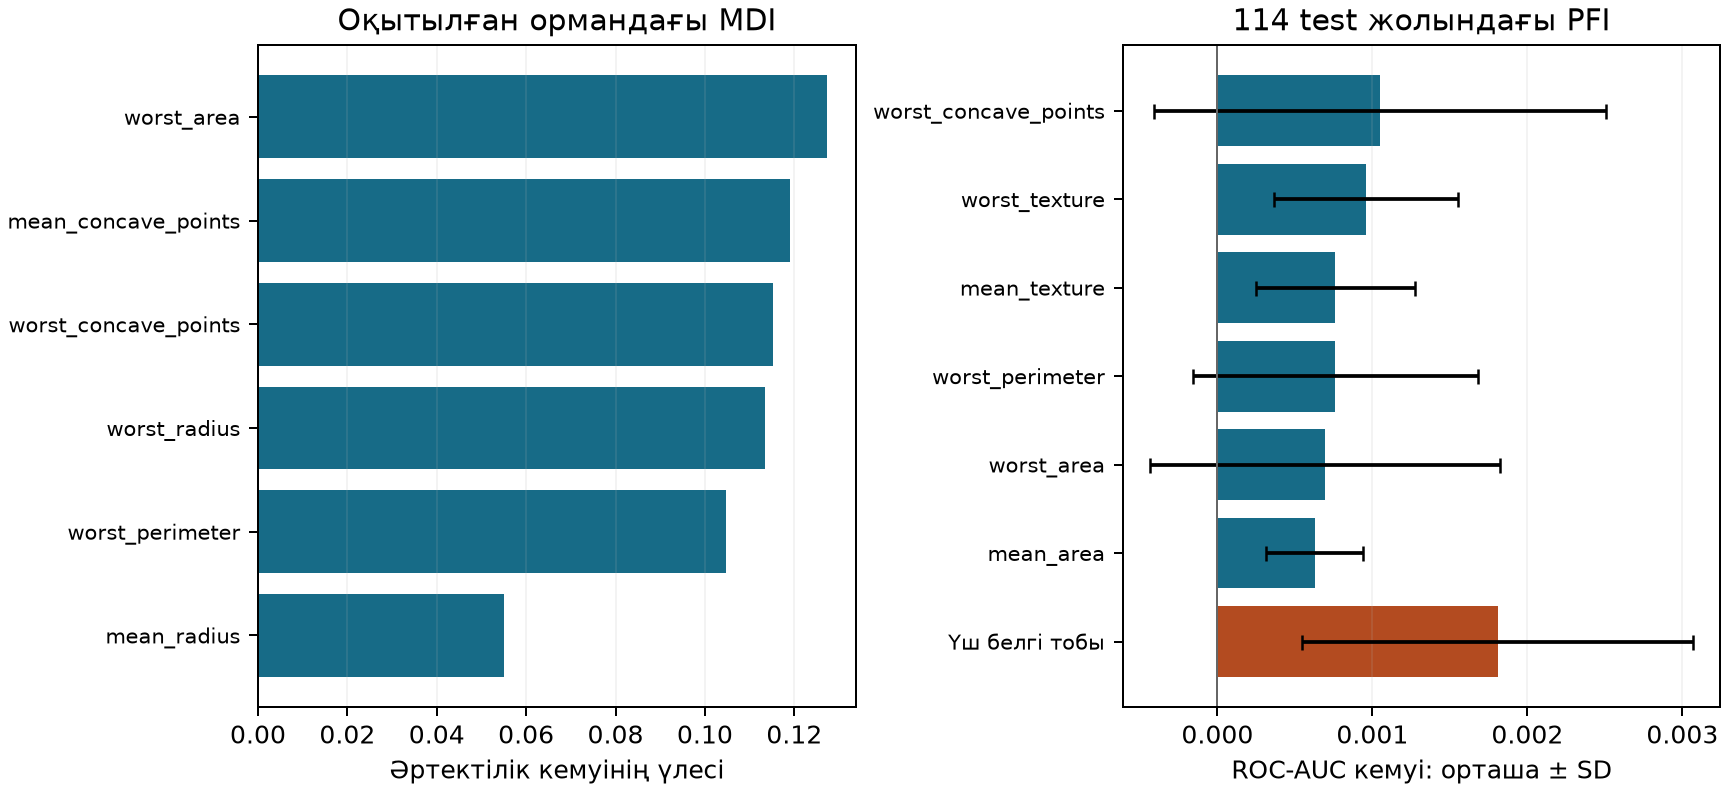

In [4]:
def grouped_permutations(model, X, y, baseline):
    rng = np.random.default_rng(2029)
    orders, drops = [], []
    for _ in range(REPEATS):
        order = rng.permutation(len(X))
        permuted = X.copy()
        permuted[GROUP] = X[GROUP].iloc[order].to_numpy()
        orders.append(order.tolist())
        drops.append(float(baseline - auc_positive(model, permuted, y)))
    return orders, drops


def global_importance(data, model):
    X, y, train, test = (data[key] for key in ("X", "y", "train", "test"))
    X_test, y_test = X.iloc[test], y[test]
    with threadpool_limits(limits=1):
        probabilities = positive_probabilities(model, X_test)
        baseline = roc_auc_score(y_test, probabilities)
        pfi = permutation_importance(model, X_test, y_test, scoring=auc_positive,
                                     n_repeats=REPEATS, random_state=2027, n_jobs=1)
        orders, group_drops = grouped_permutations(model, X_test, y_test, baseline)
    rows = [{"feature": name, "MDI": float(mdi), "PFI_mean": float(mean), "PFI_sd": float(sd),
             "PFI_drops": samples.tolist()}
            for name, mdi, mean, sd, samples in zip(X.columns, model.feature_importances_,
                                                  pfi.importances_mean, pfi.importances_std,
                                                  pfi.importances)]
    group = {"features": GROUP, "seed": 2029, "PFI_drops": group_drops,
             "PFI_mean": float(np.mean(group_drops)), "PFI_sd": float(np.std(group_drops, ddof=0)),
             "row_permutations": orders,
             "train_Pearson": X.iloc[train][GROUP].corr().to_numpy().tolist()}
    print(f"Тест ROC-AUC: {baseline:.9f}")
    rank = sorted(rows, key=lambda row: row["PFI_mean"], reverse=True)
    print(pd.DataFrame(rank[:6]).drop(columns="PFI_drops").to_string(index=False))
    print(f"Топтық PFI орташа мәні {group['PFI_mean']:.9f}, SD {group['PFI_sd']:.9f}")
    return {"baseline_ROC_AUC": float(baseline), "test_probabilities_class_1": probabilities.tolist(),
            "test_y": y_test.tolist(), "PFI_seed": 2027, "n_repeats": REPEATS,
            "PFI_sd_ddof": 0, "rows": rows, "group": group}


def plot_global(result, output):
    rows, group = result["rows"], result["group"]
    mdi = sorted(rows, key=lambda row: row["MDI"], reverse=True)[:6]
    pfi = sorted(rows, key=lambda row: row["PFI_mean"], reverse=True)[:6]
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.4), layout="constrained")
    axes[0].barh([row["feature"] for row in mdi], [row["MDI"] for row in mdi], color="#176B87")
    axes[0].set(title="Оқытылған ормандағы MDI", xlabel="Әртектілік кемуінің үлесі")
    axes[1].barh([row["feature"] for row in pfi] + ["Үш белгі тобы"],
                [row["PFI_mean"] for row in pfi] + [group["PFI_mean"]],
                xerr=[row["PFI_sd"] for row in pfi] + [group["PFI_sd"]],
                color=["#176B87"] * 6 + ["#B34B20"], capsize=3)
    axes[1].axvline(0, color="#666666", linewidth=.8)
    axes[1].set(title="114 test жолындағы PFI", xlabel="ROC-AUC кемуі: орташа ± SD")
    for axis in axes:
        axis.invert_yaxis()
        axis.tick_params(axis="y", labelsize=8.3)
        axis.grid(axis="x", alpha=.15)
    fig.savefig(output, dpi=180)
    plt.close(fig)


global_result = global_importance(data, model)
plot_global(global_result, FIGURES / "ch10_05_global_importance.png")
display(Image(filename=str(FIGURES / "ch10_05_global_importance.png")))


### Жаһандық өлшемдерді өзіндік тексеру

30 MDI мәнінің нормаланғанына көз жеткізіңіз. Үш белгінің жеке бағаларын топтық бағамен салыстырыңыз. Жолдардың ортақ реті қандай үйлесімдерді сақтайтынын түсіндіріңіз.

In [5]:
rows = global_result["rows"]
assert len(rows) == 30 and all(row["MDI"] >= 0 for row in rows)
np.testing.assert_allclose(sum(row["MDI"] for row in rows), 1.0, atol=1e-12, rtol=0)
assert all(len(row["PFI_drops"]) == REPEATS for row in rows)
orders = global_result["group"]["row_permutations"]
assert len(orders) == REPEATS
assert all(sorted(order) == list(range(len(data["test"]))) for order in orders)
print("Train ішіндегі топ корреляциялары")
print(pd.DataFrame(global_result["group"]["train_Pearson"], index=GROUP, columns=GROUP))


Train ішіндегі топ корреляциялары
                mean_radius  mean_perimeter  mean_area
mean_radius        1.000000        0.997897   0.986851
mean_perimeter     0.997897        1.000000   0.986148
mean_area          0.986851        0.986148   1.000000


### 8–9-қадамдар. Екі жергілікті түсіндірме

64 train жолынан тұратын фон seed 2028 арқылы қайтарусыз таңдалады. Test ішіндегі бастапқы row_id мәндері ең кіші екеуі түсіндіріледі. Үлестер массиві мен база 1 класы үшін алынады. Диагностикадан кейін қосынды мен орман шығысының абсолют алшақтығын 0,00001 рұқсатпен тексереміз. Базаны бөлек тексеру үшін 0,000001 рұқсат сақталады.

tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 row_id        base    sum_SHAP  reconstructed_probability  forest_probability   abs_error
      6 0.426708571 0.573287310                0.999995881         1.000000000 0.000004119
     11 0.426708571 0.573287309                0.999995880         1.000000000 0.000004120


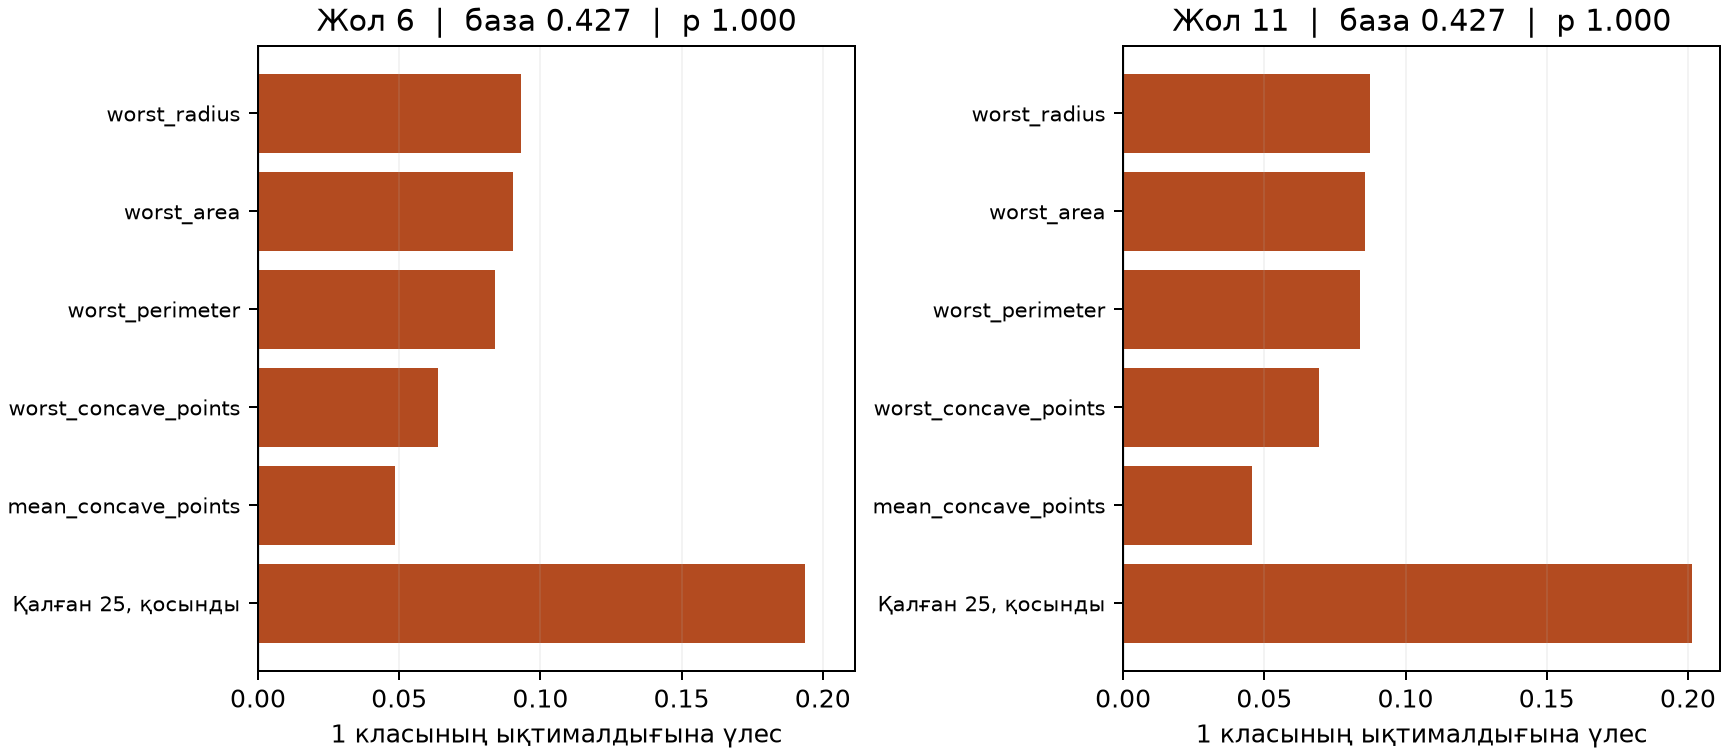

In [6]:
def local_explanations(data, model):
    import shap

    X, train, test = (data[key] for key in ("X", "train", "test"))
    rng = np.random.default_rng(2028)
    background_ids = np.sort(rng.choice(np.sort(train), size=64, replace=False))
    case_ids = np.sort(test)[:2]
    background, cases = X.iloc[background_ids], X.iloc[case_ids]
    column = int(np.flatnonzero(model.classes_ == 1)[0])
    with threadpool_limits(limits=1):
        explainer = shap.TreeExplainer(model, data=background.to_numpy(),
                                      feature_perturbation="interventional", model_output="probability")
        explanation = explainer(cases.to_numpy(), approximate=False)
        probabilities = positive_probabilities(model, cases)
        background_probability = positive_probabilities(model, background).mean()
    if explanation.values.shape != (len(cases), X.shape[1], len(model.classes_)):
        raise ValueError(f"SHAP мәндерінің пішіні күтілмеген: {explanation.values.shape}")
    if explanation.base_values.shape != (len(cases), len(model.classes_)):
        raise ValueError(f"SHAP базасының пішіні күтілмеген: {explanation.base_values.shape}")
    values = explanation.values[:, :, column]
    base_values = explanation.base_values[:, column]
    sums = values.sum(axis=1)
    reconstructed = base_values + sums
    np.testing.assert_allclose(base_values, background_probability, atol=1e-6, rtol=0)
    np.testing.assert_allclose(reconstructed, probabilities, atol=1e-5, rtol=0)
    rows = [{"row_id": int(row_id), "base": float(base), "sum_SHAP": float(total),
             "reconstructed_probability": float(rebuilt), "forest_probability": float(prob),
             "abs_error": float(abs(rebuilt - prob)), "SHAP_values_class_1": phi.tolist()}
            for row_id, base, total, rebuilt, prob, phi in
            zip(case_ids, base_values, sums, reconstructed, probabilities, values)]
    summary = pd.DataFrame(rows).drop(columns="SHAP_values_class_1")
    print(summary.to_string(index=False, float_format=lambda value: f"{value:.9f}"))
    return {"feature_names": X.columns.tolist(), "rows": rows, "background_seed": 2028,
            "background_row_ids": background_ids.tolist(), "model_output": "probability",
            "feature_perturbation": "interventional", "class_column": column,
            "probability_atol": 1e-5, "base_atol": 1e-6,
            "mean_forest_background_probability": float(background_probability),
            "max_abs_base_error": float(np.max(abs(base_values - background_probability))),
            "case_rule": "бастапқы test row_id мәндерінің ең кіші екеуі"}


def plot_local(result, output):
    fig, axes = plt.subplots(1, 2, figsize=(9.6, 4.2), sharex=True, layout="constrained")
    names = np.array(result["feature_names"])
    for axis, row in zip(axes, result["rows"]):
        values = np.asarray(row["SHAP_values_class_1"])
        largest = np.argsort(-np.abs(values), kind="stable")[:5]
        shown = values[largest]
        other = float(values.sum() - shown.sum())
        names_display = names[largest].tolist() + ["Қалған 25, қосынды"]
        all_values = np.r_[shown, other]
        axis.barh(names_display, all_values, color=np.where(all_values >= 0, "#B34B20", "#176B87"))
        axis.axvline(0, color="#555555", linewidth=.9)
        axis.set(title=f"Жол {row['row_id']}  |  база {row['base']:.3f}  |  p {row['forest_probability']:.3f}",
                 xlabel="1 класының ықтималдығына үлес")
        axis.invert_yaxis()
        axis.tick_params(axis="y", labelsize=8.3)
        axis.grid(axis="x", alpha=.15)
    fig.savefig(output, dpi=180)
    plt.close(fig)


local_result = local_explanations(data, model)
plot_local(local_result, FIGURES / "ch10_06_shap_cases.png")
display(Image(filename=str(FIGURES / "ch10_06_shap_cases.png")))


**Жауабыңыз.** Ықтималдық бірдей болғандағы екі үлестер жиынын салыстырыңыз. Үлес таңбасын және фонның рөлін түсіндіріңіз. Шығыстан абсолют қатенің екі мәнін де келтіріңіз.

_Өз қорытындыңызды жазыңыз._

### 10-қадам. Экспорт

JSON бастапқы индекстерді, базалық метриканы, барлық PFI қайталауларын, орман параметрлерін, фондық және түсіндірілетін жолдарды, жергілікті үлестерді және орта нұсқаларын қамтиды.

In [7]:
def save_results(data, model, global_result, local_result, output):
    train, test, y = (data[key] for key in ("train", "test", "y"))
    result = {"source": data["source"], "shape": list(data["X"].shape),
              "split_seed": 2026, "train_indices": train.tolist(), "test_indices": test.tolist(),
              "train_counts_0_1": np.bincount(y[train]).tolist(), "test_counts_0_1": np.bincount(y[test]).tolist(),
              "positive_class": "malignant=1", "model_fit_on_train_only": True,
              "test_used_for_model_selection": False, "model_parameters": model.get_params(),
              "global": global_result, "local": local_result,
              "runtime": {"Python": platform.python_version(), "device": "CPU",
                          "packages": {name: version(name) for name in PACKAGES},
                          "threadpoolctl_limit": 1,
                          "thread_environment": {name: os.getenv(name) for name in THREAD_ENVIRONMENT}}}
    output.write_text(json.dumps(result, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
    return result


result = save_results(data, model, global_result, local_result,
                      ROOT / "lab10_results.json")
print("Есеп жолы", ROOT / "lab10_results.json")


Есеп жолы lab10_artifacts/lab10_results.json


### Жергілікті есептеулерді өзіндік тексеру

Бөлулерді, фонның train жиынына тиістілігін және бастапқы идентификаторларды салыстырыңыз. Сақталған 30 үлестің қосындысын есептеп, орман ықтималдығымен салыстырыңыз.

In [8]:
train, test = set(result["train_indices"]), set(result["test_indices"])
assert len(train) == 455 and len(test) == 114 and not train & test
assert train | test == set(range(569))
assert set(local_result["background_row_ids"]) <= train
assert len(set(local_result["background_row_ids"])) == 64
assert [row["row_id"] for row in local_result["rows"]] == sorted(test)[:2]
for row in local_result["rows"]:
    assert len(row["SHAP_values_class_1"]) == 30
    reconstructed = row["base"] + sum(row["SHAP_values_class_1"])
    assert abs(reconstructed - row["forest_probability"]) <= local_result["probability_atol"]
assert local_result["max_abs_base_error"] <= local_result["base_atol"]
print("Бөлу, фон, жағдайларды таңдау ережесі және аддитивтілік тексерілді.")


Бөлу, фон, жағдайларды таңдау ережесі және аддитивтілік тексерілді.


### Жеке нұсқа және қорғау

Қосымша тәжірибелерді train ішкі бөліктерінде орындаңыз.

1. 10 және 30 алмастыру қайталауын салыстырыңыз.
2. ROC-AUC және average precision бойынша PFI салыстырыңыз.
3. Байланысты үш белгінің жеке және ортақ алмастыруларын салыстырыңыз.
4. 32 және 64 жолдық фондарда жергілікті түсіндірмені салыстырыңыз.
5. Екі тәуелсіз шу белгісін қосып, MDI және PFI салыстырыңыз.
6. Екі ішкі жолда бес үлесті және қалғандарының қосындысын топтауды тексеріңіз.

Жергілікті рубрика 100% құрайды. Деректер мен бөлу 15%, орман және ROC-AUC 15%, MDI/PFI 20%, топтық алмастыру 10%, SHAP 20%, интерпретация, нұсқа және қайталанымдылық 20% береді. Силлабус 7 ресми балды бөлек көрсетеді.

1. 1 класының ықтималдықтар бағаны қалай таңдалған?
2. MDI қандай кемулерден құралады?
3. PFI неге метрика мен жиынға тәуелді?
4. Жеке алмастыруда не орнында қалады?
5. Топ жолдарының ортақ реті кезінде не сақталады?
6. Жеке және топтық алмастыру нәтижелері қалай байланысты?
7. Фон қандай ережемен таңдалады?
8. Осы жұмыстағы SHAP үлесінің шкаласы қандай?
9. Аддитивтілікті тексеруге қандай шамалар кіреді?
10. Екі талдау үшін орман параметрлерін қалай салыстыруға болады?